Data Loading and Understanding


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
print("Shape:", df.shape)
print(df.columns.tolist())
df.info()

Shape: (7043, 21)
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-nu

In [7]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [ ]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


Data Processing


In [8]:
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Duplicates: 0


In [9]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("Hidden missing values:", df['TotalCharges'].isnull().sum())

Hidden missing values: 11


In [10]:
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
df = df.drop('customerID', axis=1)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


Exploratory Data Analysis

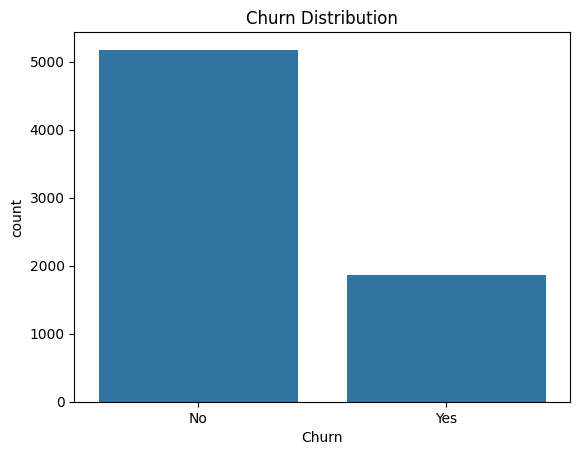

In [11]:
sns.countplot(x='Churn', data=df)
plt.title('Churn Distribution')
plt.show()

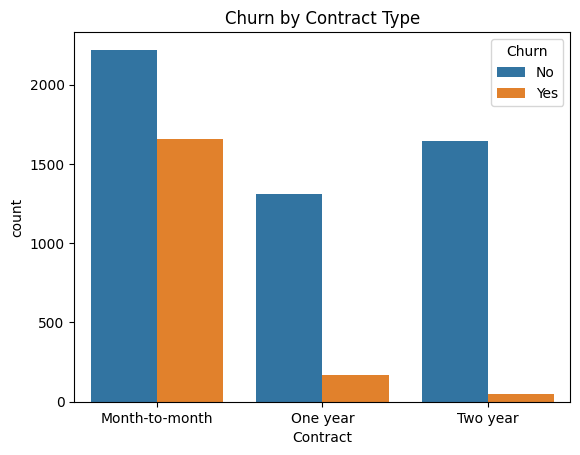

In [12]:
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title('Churn by Contract Type')
plt.show()

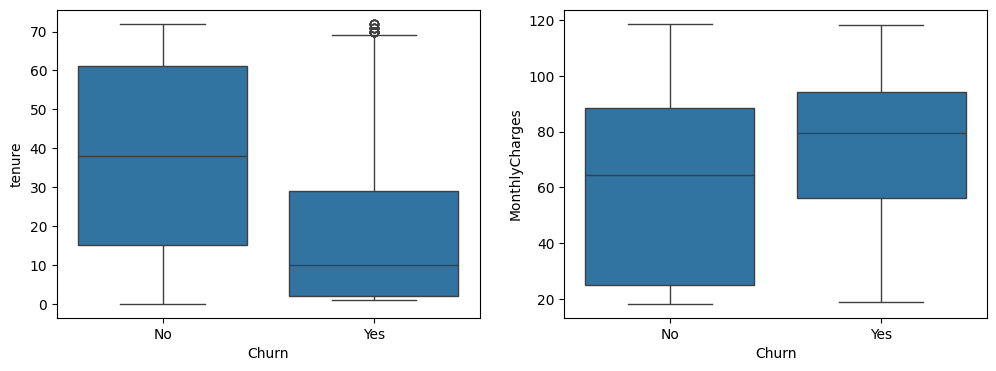

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
sns.boxplot(x='Churn', y='tenure', data=df, ax=ax[0])
sns.boxplot(x='Churn', y='MonthlyCharges', data=df, ax=ax[1])
plt.show()

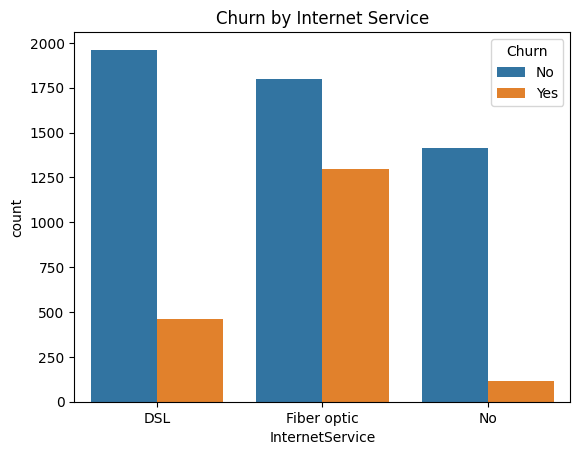

In [14]:
sns.countplot(x='InternetService', hue='Churn', data=df)
plt.title('Churn by Internet Service')
plt.show()

Feature Engineering and Encoding

In [15]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# New feature: average spend per month of tenure
df['AvgCharges'] = df['TotalCharges'] / (df['tenure'] + 1)

In [16]:
df_encoded = pd.get_dummies(df, drop_first=True)

X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']
print(X.shape, y.shape)
X.head()

(7043, 31) (7043,)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,AvgCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,14.925000,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,53.985714,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,36.050000,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,40.016304,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,50.550000,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False


Training and Testing

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [18]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_s, y_train)

dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X_train, y_train)

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
print("All models trained!")

All models trained!


Model Evaluation

In [19]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

models = {
    'Logistic Regression': (lr, X_test_s),
    'Decision Tree': (dt, X_test),
    'Random Forest': (rf, X_test)
}

results = []
for name, (model, Xt) in models.items():
    pred = model.predict(Xt)
    results.append([name,
                    accuracy_score(y_test, pred),
                    precision_score(y_test, pred),
                    recall_score(y_test, pred),
                    f1_score(y_test, pred)])

results_df = pd.DataFrame(results, columns=['Model','Accuracy','Precision','Recall','F1'])
results_df

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.808375,0.674497,0.537433,0.598214
1,Decision Tree,0.794180,0.629630,0.545455,0.584527
2,Random Forest,0.785664,0.622449,0.489305,0.547904


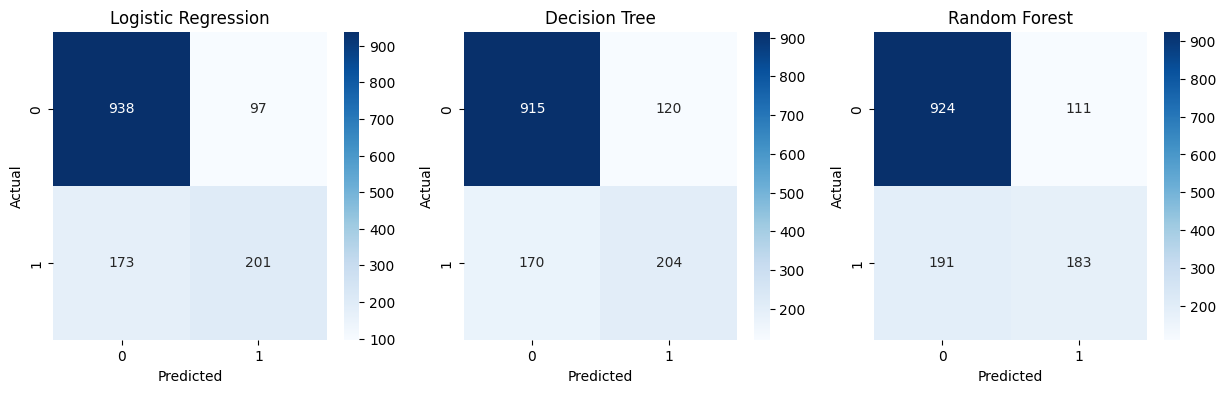

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(15,4))
for i, (name, (model, Xt)) in enumerate(models.items()):
    cm = confusion_matrix(y_test, model.predict(Xt))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[i])
    ax[i].set_title(name)
    ax[i].set_xlabel('Predicted')
    ax[i].set_ylabel('Actual')
plt.show()

Application / Prediction

In [21]:
def predict_customer(i):
    sample = X_test.iloc[[i]]
    sample_s = scaler.transform(sample)
    pred = lr.predict(sample_s)[0]
    prob = lr.predict_proba(sample_s)[0][1]
    print("Customer details:")
    print(sample[['tenure','MonthlyCharges','TotalCharges']].to_string(index=False))
    print("Prediction:", "Churn" if pred == 1 else "No Churn")
    print(f"Churn probability: {prob:.2%}")
    print("Actual:", "Churn" if y_test.iloc[i] == 1 else "No Churn")
    print("-" * 40)


stay_idx = np.where(y_test.values == 0)[0][0]
churn_idx = np.where(y_test.values == 1)[0][0]
predict_customer(stay_idx)
predict_customer(churn_idx)

Customer details:
 tenure  MonthlyCharges  TotalCharges
     72          114.05        8468.2
Prediction: No Churn
Churn probability: 4.65%
Actual: No Churn
----------------------------------------
Customer details:
 tenure  MonthlyCharges  TotalCharges
     17           45.05         770.6
Prediction: No Churn
Churn probability: 33.05%
Actual: Churn
----------------------------------------
